# 4. PREPARE, and one step of the qubitized walk

SELECT applies the terms of $H = \sum_l c_l P_l$ (notebook 03). PREPARE has to weight them: put $\sum_l \sqrt{|c_l|/\lambda}\,|l\rangle$ in an index register. How do you load an arbitrary list of weights with few Toffolis, and what does one full step of the walk that phase estimation runs cost?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pennylane.estimator as qre

from qcost.alias import alias_tables, mu_for, prepare_toffolis, prepared_distribution
from qcost.exact import spectrum, tfim
from qcost.walk import walk_calls, walk_matrix, walk_toffolis

## The recipe: alias sampling

The classical alias method (Walker, 1977) cuts any distribution over $L$ items into $L$ equal buckets, each holding at most two items: item $l$ keeps a share $\text{keep}_l/2^\mu$ of its own bucket and hands the rest to an alias $\text{alt}_l$. Six weights:

keep: [16 12 14 10  6  4]  (out of 16 )
alt:  [0 0 0 0 0 1]
target  : [0.4  0.25 0.15 0.1  0.06 0.04]
prepared: [0.3958 0.25   0.1458 0.1042 0.0625 0.0417]
max error 0.004166666666666707 <= 1/(2^mu L) = 0.010416666666666666


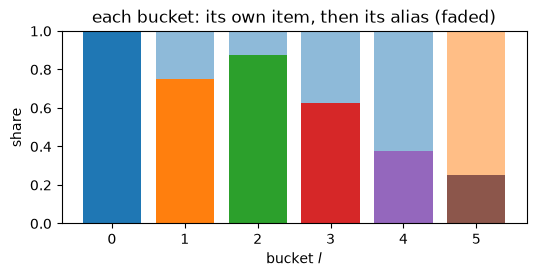

In [2]:
w = np.array([0.40, 0.25, 0.15, 0.10, 0.06, 0.04])
mu = 4
keep, alt, n = alias_tables(w, mu)
print("keep:", keep, " (out of", 2**mu, ")")
print("alt: ", alt)
p = prepared_distribution(keep, alt, mu)
print("target  :", np.round(w / w.sum(), 4))
print("prepared:", np.round(p, 4))
print("max error", np.abs(p - w / w.sum()).max(), "<= 1/(2^mu L) =", 1 / (2**mu * len(w)))

fig, ax = plt.subplots(figsize=(6, 2.5))
for l in range(len(w)):
    ax.bar(l, keep[l] / 2**mu, color=f"C{l}")
    ax.bar(l, 1 - keep[l] / 2**mu, bottom=keep[l] / 2**mu, color=f"C{alt[l]}", alpha=0.5)
ax.set_xlabel("bucket $l$")
ax.set_ylabel("share")
ax.set_title("each bucket: its own item, then its alias (faded)");

To sample: pick a bucket $l$ uniformly, pick $\sigma$ uniformly in $[0, 2^\mu)$, and output $l$ if $\sigma < \text{keep}_l$, else $\text{alt}_l$. Babbush et al. [[arXiv:1805.03662](https://arxiv.org/abs/1805.03662), Sec. III D, Fig. 11] run exactly this on superpositions:

1. uniform superposition over $l$ and over $\sigma$;
2. a QROM writes $(\text{keep}_l, \text{alt}_l)$ next to $l$: $L - 1$ Toffolis (notebook 03);
3. a comparator flags $\sigma \ge \text{keep}_l$: $\mu$ Toffolis (notebook 02);
4. controlled on the flag, swap $l$ with $\text{alt}_l$: $\lceil\log_2 L\rceil$ Toffolis.

The garbage registers ($\sigma$, keep, alt) are entangled with $l$, but SELECT only reads $l$, and PREPARE$^\dagger$ undoes them, so the block encoding is unaffected. Each probability lands within $1/(2^\mu L)$ of its target [Eq. 35], and the energy error this causes stays below $\epsilon$ for $\mu = \lceil\log_2(2\sqrt2\lambda/\epsilon)\rceil$ [Eq. 36]:

In [3]:
H = tfim(100)
mu = mu_for(H.one_norm, 0.01)
print("TFIM, 100 spins: L =", H.L, " lambda =", H.one_norm, " mu =", mu)
for k, v in prepare_toffolis(H.L, mu).items():
    print(f"  {k:24} {v:5d}")

TFIM, 100 spins: L = 199  lambda = 199.0  mu = 16
  uniform superposition       29
  QROM for keep, alt         198
  comparator                  16
  controlled swap              8
  total                      251


The QROM dominates: alias sampling costs about $L + \mu$ Toffolis, i.e. $4(L+\mu) + O(\log L)$ T gates as the paper writes it. The uniform superposition over a number of items that is not a power of 2 needs one rotation and one round of amplitude amplification (notebook 01); its cost is from Lee et al. [[arXiv:2011.03494](https://arxiv.org/abs/2011.03494), App. C, step 1(a)].

PennyLane's `AliasSampling` follows the same paper and counts more:

In [4]:
def pennylane_counts(op):
    counts = {str(k): v for k, v in qre.estimate(op).gate_counts.items()}
    return counts.get("Toffoli", 0), counts.get("T", 0)

for L in (16, 199):
    tof, t = pennylane_counts(qre.AliasSampling(L))
    print(f"L = {L:3d}: ours {prepare_toffolis(L, 16)['total']:4d} Toffolis; PennyLane {tof} Toffolis + {t} T")

L =  16: ours   35 Toffolis; PennyLane 77 Toffolis + 0 T
L = 199: ours  251 Toffolis; PennyLane 453 Toffolis + 88 T


The difference is bookkeeping, not physics: PennyLane erases its lookup inside each call (a QROM that restores its output) and synthesizes the uniform-superposition rotation in T gates, while here the lookup output stays until PREPARE$^\dagger$ undoes it with the rest. Both are order $L$.

## The walk, and why its spectrum carries the energy

Put the pieces together. With $\text{PREP}|0\rangle = \sum_l \sqrt{|c_l|/\lambda}\,|l\rangle$ and $\text{SELECT} = \sum_l |l\rangle\langle l|\otimes \text{sign}(c_l) P_l$,
$$\big(\langle 0|\otimes 1\big)\,\text{PREP}^\dagger\,\text{SELECT}\,\text{PREP}\,\big(|0\rangle\otimes 1\big) = \frac{1}{\lambda}\sum_l c_l P_l = \frac{H}{\lambda}.$$
That is a block encoding (notebook 01). Multiply by the reflection $R = 2|0\rangle\langle0| - 1$ on the index register, and the walk $W = R\,\text{PREP}^\dagger\,\text{SELECT}\,\text{PREP}$ has eigenvalues $e^{\pm i\arccos(E_k/\lambda)}$ for every eigenvalue $E_k$ of $H$ [Low and Chuang, [arXiv:1610.06546](https://arxiv.org/abs/1610.06546)]. Build it as a matrix for 4 spins and look:

W is unitary: True   size (128, 128)
every arccos(E_k / lambda) is a phase of W, to within 4.440892098500626e-16


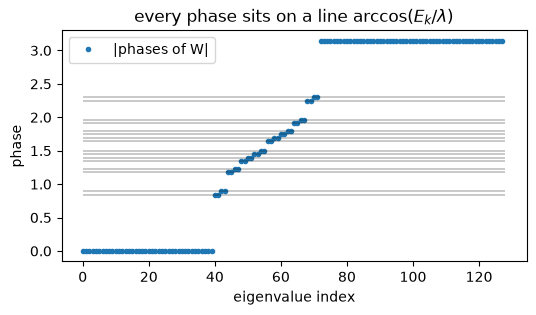

In [5]:
Hs = tfim(4, h=0.7)
E = spectrum(Hs)
W = walk_matrix(Hs)
phases = np.angle(np.linalg.eigvals(W))
print("W is unitary:", np.allclose(W.conj().T @ W, np.eye(len(W))), "  size", W.shape)
print("every arccos(E_k / lambda) is a phase of W, to within",
      max(np.min(np.abs(np.abs(phases) - np.arccos(e / Hs.one_norm))) for e in E))

plt.figure(figsize=(6, 3))
plt.plot(np.sort(np.abs(phases)), "o", ms=3, label="|phases of W|")
plt.hlines(np.arccos(E / Hs.one_norm), 0, len(phases), colors="k", lw=0.3)
plt.ylabel("phase")
plt.xlabel("eigenvalue index")
plt.legend()
plt.title(r"every phase sits on a line $\arccos(E_k/\lambda)$");

Each of the 16 energies gives two phases, $\pm\arccos(E_k/\lambda)$: 32 of the 128 eigenvalues. The other 96 are $\pm 1$ (phases $0$ and $\pi$, the flat ends of the plot): they live on states that a start from $|0\rangle|\psi\rangle$ never reaches, so phase estimation does not see them.

Why it works, in one sentence: for each eigenvector $|k\rangle$ of $H$, the walk maps the plane spanned by $|0\rangle|k\rangle$ and $W|0\rangle|k\rangle$ to itself and acts there as a rotation by $\arccos(E_k/\lambda)$, the 2D picture of notebook 01 again.

## What phase estimation pays

Phase estimation on $W$ reads $\arccos(E_0/\lambda)$, and $|d\arccos(E/\lambda)/dE| \ge 1/\lambda$, so an energy error $\epsilon$ needs a phase error about $\epsilon/\lambda$, and the number of walk steps grows like $\lambda/\epsilon$:
$$\text{walk calls} = \left\lceil \frac{\pi\lambda}{2\epsilon} \right\rceil$$
in Lee et al. [arXiv:2011.03494, Eq. 45]. Babbush et al. define $\epsilon$ as a root-mean-square error instead and need $\sqrt2\pi\lambda/\epsilon$ [arXiv:1805.03662, Eq. 26]; notebook 07 uses their convention to reproduce their numbers.

## One step, itemized

A step is SELECT, PREPARE, PREPARE$^\dagger$ and the reflection, which acts on the $\lceil\log_2 L\rceil$ index qubits and the $\mu$ qubits of $\sigma$, controlled by one more qubit for phase estimation; a NOT with $n$ controls costs $n - 1$ Toffolis [Gidney, [arXiv:1709.06648](https://arxiv.org/abs/1709.06648), p. 5]:

In [6]:
step = walk_toffolis(H, eps=0.01)
for k, v in step.items():
    print(f"  {k:16} {v:5d}")
print(f"walk calls {walk_calls(H.one_norm, 0.01)}, total {walk_calls(H.one_norm, 0.01) * step['total']:.3g} Toffolis")
pauli = qre.PauliHamiltonian(num_qubits=100, pauli_terms={"XX": 99, "Z": 100}, one_norm=H.one_norm)
walk = qre.Qubitization(qre.AliasSampling(H.L), qre.SelectPauli(pauli))
print("PennyLane walk step:", pennylane_counts(walk), "(Toffolis, T)")

  SELECT             198
  PREPARE            251
  PREPARE inverse    251
  reflection          24
  total              724
  mu                  16
walk calls 31259, total 2.26e+07 Toffolis
PennyLane walk step: (960, 176) (Toffolis, T)


The walk step is about $3L$ Toffolis: $L$ for SELECT and $L$ for each PREPARE. For the Ising chain every term has the same size, and a PREPARE that knows this is almost free; the generic alias sampler pays for not knowing. Notebook 07 shows how much such structure saves for the Hubbard model.

## Exercises

1. Make the weights very uneven: $w_l \propto 2^{-l}$ for $L = 20$. Do the alias tables still have one alias per bucket? What happens to the error bound?
2. Check numerically that for $\mu = $ `mu_for(lambda, eps)`, the energy $\sum_l \tilde\rho_l\lambda\langle P_l\rangle$ computed with the prepared distribution differs from the exact ground energy by less than $\epsilon$, for the 4-spin chain.
3. Write a PREPARE for the TFIM that uses its structure: two groups of equal coefficients ($-1$ on $XX$ bonds, $-h$ on $Z$ sites). What does a walk step cost now? (Hint: one rotation to split the two groups, then uniform superpositions.)